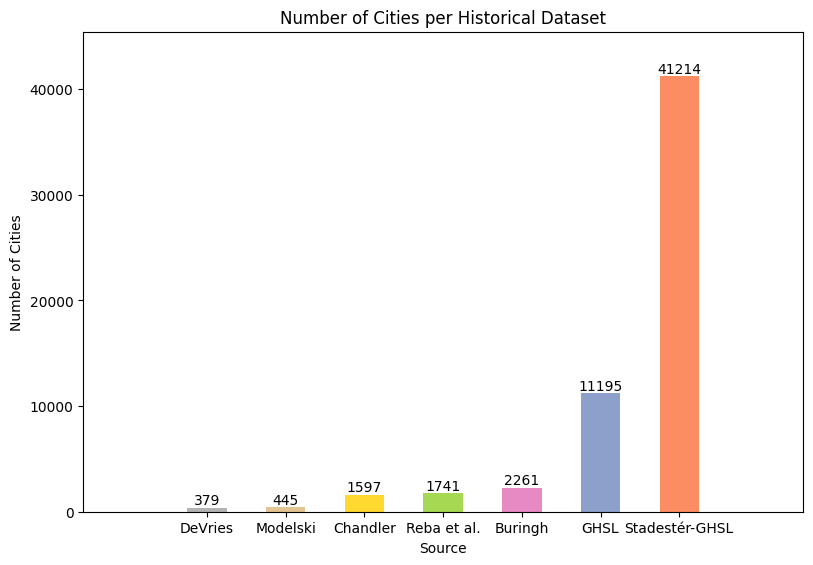

In [131]:
import json
import matplotlib.pyplot as plt
import pandas as pd

# Your data processing code remains the same...
data = """
{
  "buringh": 2261,
  "chandler_modelski": 1741,
  "devries": 379,
  "ghsl": 11195,
  "chandler": 1597,
  "modelski": 445,
  "stadester_total": 41214
}
"""

cities_data = json.loads(data)
df = pd.DataFrame(list(cities_data.items()), columns=['source', 'count'])
df = df.sort_values('count')

readable_names = {
    "buringh": "Buringh",
    "chandler_modelski": "Reba et al.",
    "devries": "DeVries",
    "ghsl": "GHSL",
    "chandler": "Chandler",
    "modelski": "Modelski",
    "stadester_total": "Stadestér-GHSL"
}

df['readable_source'] = df['source'].map(readable_names)
sources = df['readable_source']
counts = df['count']

# Create larger figure
fig = plt.figure(figsize=(12, 8))  # Significantly larger
ax = fig.add_axes([0.2, 0.2, 0.6, 0.6])  # Smaller relative size = more whitespace

colors = plt.cm.Set2_r(range(len(sources)))
bars = ax.bar(sources, counts, color=colors, width=0.5)

ax.set_xlabel("Source")
ax.set_ylabel("Number of Cities")
ax.set_title("Number of Cities per Historical Dataset")
ax.set_xticks(sources)
ax.set_xticklabels(sources, rotation=0, ha="center")

# Adjust x-axis limits for padding
x_min = ax.get_xlim()[0]
x_max = ax.get_xlim()[1]
padding = 1
ax.set_xlim(x_min - padding, x_max + padding)

# Adjust y-axis limits for vertical padding
y_max = ax.get_ylim()[1]
y_padding_factor = 1.05  # Increase by 10%
ax.set_ylim(0, y_max * y_padding_factor)

for bar in bars:
    yval = bar.get_height()
    # Adjust text placement to be on top of the bar and vertically aligned with a trailing space
    ax.text(bar.get_x() + bar.get_width()/2, yval, str(int(yval)), va='bottom', ha='center', rotation=0) #rotation=90 for vertical


# Force matplotlib to preserve the whitespace

plt.savefig('plot_with_whitespace.png', bbox_inches=None, dpi=150)

plt.show()